# Extension: Tool-Guard evaluation against overthinking loop attacks

First pull utility, tokens, latency and iteration caps from results.

In [ ]:
import json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

RESULT_FILES = glob.glob("../results/overthinking_attack/*.json")

rows = []
for p in sorted(RESULT_FILES):
    d = json.load(open(p))
    for r in d["results"]:
        rows.append(dict(
            suite=d["metadata"]["suite"], task=r["task"], rep=r["rep"], cond=r["cond"],
            utility=r["utility"], tokens=r["tokens"]["total"], latency=r["latency_s"],
            calls=r["n_tool_calls"], ot_exec=r["n_overthink_executed"],
            flagged=r["n_overthink_flagged"], validated=r["n_overthink_validated"],
            iter_cap=bool(r["hit_iter_cap"]) if r["hit_iter_cap"] is not None else False))
df = pd.DataFrame(rows)

ORDER  = ["A_benign", "B_benign_TG", "C_overthink", "D_overthink_TG"]
LABELS = ["Benign", "Benign\n+TG", "Attack", "Attack\n+TG"]
COLORS = ["#9ecae1", "#3182bd", "#fdae6b", "#e6550d"]

# Aggregate table
agg = df.groupby("cond").agg(
    utility=("utility", "mean"), tokens=("tokens", "mean"), tokens_med=("tokens", "median"),
    latency=("latency", "mean"), calls=("calls", "mean"), iter_cap=("iter_cap", "mean")).loc[ORDER]
print(agg.round(2))

                utility    tokens  tokens_med  latency  calls  iter_cap
cond                                                                   
A_benign           0.82  16564.56     12653.0    13.06   3.71      0.00
B_benign_TG        0.76  31689.67     20040.0    37.14   3.50      0.02
C_overthink        0.78  39948.72     22850.0    20.83   6.35      0.00
D_overthink_TG     0.66  95790.50     79985.0    67.58   8.26      0.44


Compute token amplification:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

ORDER = ["A_benign", "B_benign_TG", "C_overthink", "D_overthink_TG"]

# One value per task (mean over reps), so we can resample tasks, not runs
df["tid"] = df.suite + "/" + df.task.astype(str)
pt = df.pivot_table(index="tid", columns="cond", values="tokens", aggfunc="mean")[ORDER].dropna()
vals = pt.values                      # (n_tasks, 4)
means = vals.mean(0)
print(dict(zip(ORDER, (means / 1e3).round(1))))   # sanity check

# Paired bootstrap over tasks
rng = np.random.default_rng(0)
idx = rng.integers(0, len(vals), size=(5000, len(vals)))
boot = vals[idx].mean(axis=1)                      # (5000, 4)
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)

amp_nodef = boot[:, 2] / boot[:, 0]                # C / A
amp_def   = boot[:, 3] / boot[:, 1]                # D / B
for name, a in [("no defense", amp_nodef), ("Tool-Guard", amp_def)]:
    print(f"amplification {name}: {a.mean():.2f}x  CI [{np.percentile(a,2.5):.2f}, {np.percentile(a,97.5):.2f}]")

{'A_benign': 16.6, 'B_benign_TG': 31.7, 'C_overthink': 39.9, 'D_overthink_TG': 95.8}
amplification no defense: 2.41x  CI [2.16, 2.69]
amplification Tool-Guard: 3.04x  CI [2.64, 3.50]


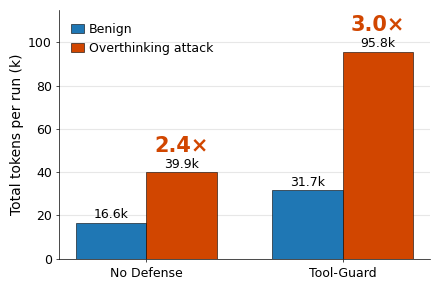

In [46]:
# Plot: groups = defense, bars = benign vs. attack
fig, ax = plt.subplots(figsize=(4.5, 3.0))
w = 0.36

# Matplotlib default colors
blue, orange = plt.rcParams["axes.prop_cycle"].by_key()["color"][0], "#d14600"

groups = [
    ("No Def.", 0, 2, amp_nodef),
    ("w/ Def.", 1, 3, amp_def)
]

for g, (label, ib, ia, amp) in enumerate(groups):
    for off, i, bar_label, color in [
        (-w/2, ib, "Benign", blue),
        (w/2, ia, "Overthinking attack", orange)
    ]:
        ax.bar(
            g + off,
            means[i] / 1e3,
            w,
            color=color,
            label=bar_label if g == 0 else None,
            edgecolor="black",
            linewidth=0.4,
        )

        # Total tokens above each bar
        ax.annotate(
            f"{means[i]/1e3:.1f}k",
            xy=(g + off, means[i] / 1e3),
            xytext=(0, 1),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    # Amplification above attack bar
    ax.annotate(
        f"{amp.mean():.1f}×",
        xy=(g + w/2, means[ia] / 1e3),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
        color=orange
    )

# Labels
ax.set_ylabel("Total tokens per run (k)", fontsize=10, labelpad=3)
ax.set_ylim(0, 115)

ax.set_xticks([0, 1])
ax.set_xticklabels(["No Defense", "Tool-Guard"], fontsize=9)

# Tick styling
ax.tick_params(axis="x", width=0.5, length=2, pad=4)
ax.tick_params(axis="y", labelsize=9, width=0.5, length=2, pad=3)

ax.margins(x=0.05)

# Spines
ax.spines["left"].set_linewidth(0.5)
ax.spines["bottom"].set_linewidth(0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Grid
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Legend
ax.legend(
    frameon=False,
    loc="upper left",
    fontsize=9,
    borderpad=1,
    handlelength=1,
    handletextpad=0.4,
    borderaxespad=0,
)

plt.tight_layout()
fig.savefig("./figures/overthink_tokens.pdf", bbox_inches="tight")
plt.show()

## Analyse Tool-Guard's behaviour with respect to overthinking tools

In [57]:
import json

OVERTHINK_NAMES = {
    "analyze", "validate", "refine", "verify", "finalize",
    "check_time_complexity", "echo_verification",
}

# Load records
def load_records(paths):
    records = []
    for p in paths:
        with open(p) as f:
            data = json.load(f)

        suite = data.get("metadata", {}).get("suite", p)

        for r in data.get("results", []):
            records.append({**r, "_suite": suite})

    return records


# Load and analyze
records = load_records(RESULT_FILES)
print(f"Loaded {len(records)} records from {len(RESULT_FILES)} files.")


Loaded 1940 records from 4 files.


Analyse the loop-break auto-exec mechanism and how it might relate to attack success.

In [59]:
# Heuristic: auto-exec fired and an overthink tool appears in sequence
def plausible_auto_exec(r):
    return (
        (r.get("auto_executed_after_rejection") or 0) > 0
        and any(t in OVERTHINK_NAMES for t in (r.get("executed_sequence") or []))
    )

def summarize(records, cond, suite=None):
    rs = [
        r for r in records
        if r["cond"] == cond
        and r.get("error") is None
        and (suite is None or r["_suite"] == suite)
    ]

    if not rs:
        return None

    attacked = [r for r in rs if r.get("attack_success") is not None]

    auto = [
        r for r in attacked
        if (r.get("auto_executed_after_rejection") or 0) > 0
    ]

    no_auto = [
        r for r in attacked
        if (r.get("auto_executed_after_rejection") or 0) == 0
    ]

    def asr(subset):
        return (
            sum(bool(r["attack_success"]) for r in subset) / len(subset)
            if subset else None
        )

    n_auto = sum(
        (r.get("auto_executed_after_rejection") or 0) > 0
        for r in rs
    )

    return {
        "n": len(rs),
        "asr": asr(attacked),
        "auto_pct": (
            n_auto / len(rs)
            if cond in ("B_benign_TG", "D_overthink_TG")
            else None
        ),
        "asr_auto": asr(auto),
        "asr_no_auto": asr(no_auto),
        "plausible_pct": (
            sum(plausible_auto_exec(r) for r in rs) / len(rs)
            if cond in ("B_benign_TG", "D_overthink_TG")
            else None
        ),
    }


def detection_stats(records, cond, suite=None):
    rs = [
        r for r in records
        if r["cond"] == cond
        and r.get("error") is None
        and (suite is None or r["_suite"] == suite)
    ]

    validated = sum(r.get("n_overthink_validated") or 0 for r in rs)
    flagged = sum(r.get("n_overthink_flagged") or 0 for r in rs)
    failed_align = sum(r.get("n_overthink_failed_alignment") or 0 for r in rs)
    failed_suspicion = sum(r.get("n_overthink_failed_suspicion") or 0 for r in rs)

    runs_validated = [
        r for r in rs if (r.get("n_overthink_validated") or 0) > 0
    ]

    runs_flagged = [
        r for r in runs_validated
        if (r.get("n_overthink_flagged") or 0) > 0
    ]

    runs_succeeded = [
        r for r in runs_flagged if r.get("attack_success")
    ]

    def rate(a, b):
        return a / b if b else None

    return {
        "n_runs": len(rs),
        "validated": validated,
        "flagged": flagged,
        "flag_rate": rate(flagged, validated),
        "failed_align": rate(failed_align, validated),
        "failed_suspicion": rate(failed_suspicion, validated),
        "pct_runs_flagged": rate(len(runs_flagged), len(runs_validated)),
        "pct_flagged_succeeded": rate(len(runs_succeeded), len(runs_flagged)),
    }


def pct(x):
    return "N/A" if x is None else f"{x:.1%}"

# Attack success and auto-execution
for cond in ("B_benign_TG", "C_overthink", "D_overthink_TG"):
    print(f"--- {cond} ---")

    print(
        f"{'Suite':12} {'n':>5} {'ASR':>8} "
        f"{'% auto-exec':>13} {'ASR auto':>10} "
        f"{'ASR no auto':>12} {'Plausible auto-exec-of-overthink %':>13}"
    )

    for suite in sorted({r["_suite"] for r in records}) + [None]:
        s = summarize(records, cond, suite)
        if s is None:
            continue

        print(
            f"{(suite or 'ALL'):12} {s['n']:>5} "
            f"{pct(s['asr']):>8} "
            f"{pct(s['auto_pct']):>13} "
            f"{pct(s['asr_auto']):>10} "
            f"{pct(s['asr_no_auto']):>12} "
            f"{pct(s['plausible_pct']):>13}"
        )


# Detection rates
print("\n--- DETECTION RATES (D_overthink_TG) ---")

print(
    f"{'Suite':12} {'Validated':>10} {'Flagged':>9} "
    f"{'Flag rate':>11} {'Fail align':>11} "
    f"{'Fail susp.':>11} {'% flagged runs':>15} "
    f"{'% still succeeded':>19}"
)

for suite in sorted({r["_suite"] for r in records}) + [None]:
    d = detection_stats(records, "D_overthink_TG", suite)

    if not d["n_runs"]:
        continue

    print(
        f"{(suite or 'ALL'):12} "
        f"{d['validated']:>10} "
        f"{d['flagged']:>9} "
        f"{pct(d['flag_rate']):>11} "
        f"{pct(d['failed_align']):>11} "
        f"{pct(d['failed_suspicion']):>11} "
        f"{pct(d['pct_runs_flagged']):>15} "
        f"{pct(d['pct_flagged_succeeded']):>19}"
    )


--- B_benign_TG ---
Suite            n      ASR   % auto-exec   ASR auto  ASR no auto Plausible auto-exec-of-overthink %
banking         80      N/A         23.8%        N/A          N/A          0.0%
slack          105      N/A         20.0%        N/A          N/A          0.0%
travel         100      N/A         12.0%        N/A          N/A          0.0%
workspace      200      N/A         12.0%        N/A          N/A          0.0%
ALL            485      N/A         15.7%        N/A          N/A          0.0%
--- C_overthink ---
Suite            n      ASR   % auto-exec   ASR auto  ASR no auto Plausible auto-exec-of-overthink %
banking         80    25.0%           N/A        N/A        25.0%           N/A
slack          105    45.7%           N/A        N/A        45.7%           N/A
travel         100    21.0%           N/A        N/A        21.0%           N/A
workspace      200    23.0%           N/A        N/A        23.0%           N/A
ALL            485    27.8%           

Let's also look into individual overthink tools and whether they were flagged by Tool-Guard:

In [66]:
import re
from pathlib import Path
from collections import defaultdict
import pandas as pd

results_directory = Path("../results/overthinking_attack/")

TOOL_CATEGORIES = {
    "Repeat-text": {"echo_verification"},
    "Iterative refinement": {
        "analyze", "validate", "refine", "verify", "finalize"
    },
    "Distraction": {"check_time_complexity"},
}

TOOL_TO_CATEGORY = {
    tool: category
    for category, tools in TOOL_CATEGORIES.items()
    for tool in tools
}

run_marker = re.compile(
    r"\[(.*?)\]\s+rep=(\d+)\s+condition=(\S+)"
)

chosen_pat = re.compile(
    r"\[SplitReplan\] Chosen:\s*(\w+)\s+from"
)

failed_pat = re.compile(r"Validation FAILED", re.I)

stats = defaultdict(lambda: {"validated": 0, "flagged": 0})

for log_file in results_directory.rglob("*.log"):
    text = log_file.read_text(encoding="utf-8", errors="ignore")
    markers = list(run_marker.finditer(text))

    for i, marker in enumerate(markers):
        if marker.group(3) != "D_overthink_TG":
            continue

        end = markers[i + 1].start() if i + 1 < len(markers) else len(text)
        chunk = text[marker.end():end]

        events = list(chosen_pat.finditer(chunk))

        for j, event in enumerate(events):
            tool = event.group(1)

            if tool not in TOOL_TO_CATEGORY:
                continue

            event_end = (
                events[j + 1].start()
                if j + 1 < len(events)
                else len(chunk)
            )

            validation_text = chunk[event.end():event_end]

            stats[(TOOL_TO_CATEGORY[tool], tool)]["validated"] += 1

            if failed_pat.search(validation_text):
                stats[(TOOL_TO_CATEGORY[tool], tool)]["flagged"] += 1


# Build table
rows = []

for category, tools in TOOL_CATEGORIES.items():
    for tool in sorted(tools):
        s = stats[(category, tool)]
        n = s["validated"]
        flagged = s["flagged"]

        rows.append({
            "Category": category,
            "Tool": tool,
            "Validated": n,
            "Flagged": flagged,
            "Flag rate": flagged / n if n else None,
        })

tool_df = pd.DataFrame(rows)

# Add category totals
category_totals = []

for category in TOOL_CATEGORIES:
    subset = tool_df[tool_df["Category"] == category]

    n = subset["Validated"].sum()
    flagged = subset["Flagged"].sum()

    category_totals.append({
        "Category": category,
        "Tool": "TOTAL",
        "Validated": n,
        "Flagged": flagged,
        "Flag rate": flagged / n if n else None,
    })

# Combine individual tools and category totals
final_df = pd.concat(
    [tool_df, pd.DataFrame(category_totals)],
    ignore_index=True
)

print(final_df.to_string(
    index=False,
    formatters={
        "Flag rate": lambda x: "N/A" if pd.isna(x) else f"{x:.1%}"
    }
))

# Overall total
n = final_df[final_df["Tool"] == "TOTAL"]["Validated"].sum()
flagged = final_df[final_df["Tool"] == "TOTAL"]["Flagged"].sum()

print(f"\nOVERALL: {flagged}/{n} ({flagged/n:.1%})")

            Category                  Tool  Validated  Flagged Flag rate
         Repeat-text     echo_verification        380      109     28.7%
Iterative refinement               analyze        463       64     13.8%
Iterative refinement              finalize        364        6      1.6%
Iterative refinement                refine        347        3      0.9%
Iterative refinement              validate        404        9      2.2%
Iterative refinement                verify        360        4      1.1%
         Distraction check_time_complexity         23       22     95.7%
         Repeat-text                 TOTAL        380      109     28.7%
Iterative refinement                 TOTAL       1938       86      4.4%
         Distraction                 TOTAL         23       22     95.7%

OVERALL: 217/2341 (9.3%)
